_HAMRIT Wassim_ 
_5A FISE D1_

# **Rapport - Utilisation de plusieurs méthodes pour compter l'occurence des mots d'un texte**


Dans ce rapport, on va étudier plusieurs méthodes permettant de compter les mots dans un fichier texte. <br><br>
On va s'intéresser à **3 méthodes** différentes: 

- Une méthode simple en utilisant du code Python en traitant les données de manière **séquetielle**.
- Une méthode **pseudo-MapReduce** qui reproduit les étapes du MapReduce (map, shuffle, reduce) en utilisant Python.
- Une méthode qui s'appuie sur le parallélisme en utilisant **Hadoop MapReduce**.

Pour chacune de ces méthodes, on va utiliser plusieurs fichiers texte en faisant varier leur nombre de lignes:
- **N = 100 lignes** 
- **N = 100 000 lignes** 
- **N = 5 000 000 lignes** 
- **N = 50 000 000 lignes** 



En utilisant ces fichiers texte de différentes tailles, on pourra donc étudier les différences de performance entre chaque méthodes selon la quantité des données.

## **1 - Méthode séquentielle avec Python**


#### a) Fichier de taille N = 100 lignes

In [41]:
import time

def compter_occurrences(fichier):
    with open (fichier , 'r', encoding='utf -8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot , 0) + 1
    return compteur

debut = time.perf_counter();

fichier = "./textes/fichier1_100.txt"
resultats = compter_occurrences(fichier)
for mot , nb in sorted (resultats.items(), key= lambda x: x[1], reverse=True):
    print (f"{ mot} : {nb}")

fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 23
voiture : 22
chien : 21
arbre : 18
maison : 16

Temps d'exécution : 0.01228s


#### b) Fichier de taille N = 100 000 lignes

In [42]:
import time

def compter_occurrences(fichier):
    with open (fichier , 'r', encoding='utf -8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot , 0) + 1
    return compteur

debut = time.perf_counter();

fichier = "./textes/fichier2_100k.txt"
resultats = compter_occurrences(fichier)
for mot , nb in sorted (resultats.items(), key= lambda x: x[1], reverse=True):
    print (f"{ mot} : {nb}")

fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 23000
voiture : 22000
chien : 21000
arbre : 18000
maison : 16000

Temps d'exécution : 0.04713s


#### c) Fichier de taille N = 5 000 000 lignes

In [43]:
import time

def compter_occurrences(fichier):
    with open (fichier , 'r', encoding='utf -8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot , 0) + 1
    return compteur

debut = time.perf_counter();

fichier = "./textes/fichier3_5M.txt"
resultats = compter_occurrences(fichier)
for mot , nb in sorted (resultats.items(), key= lambda x: x[1], reverse=True):
    print (f"{ mot} : {nb}")

fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 1150000
voiture : 1100000
chien : 1050000
arbre : 900000
maison : 800000

Temps d'exécution : 0.71780s


#### d) Fichier de taille N = 50 000 000 lignes

In [44]:
import time

def compter_occurrences(fichier):
    with open (fichier , 'r', encoding='utf -8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot , 0) + 1
    return compteur

debut = time.perf_counter();

fichier = "./textes/fichier4_50M.txt"
resultats = compter_occurrences(fichier)
for mot , nb in sorted (resultats.items(), key= lambda x: x[1], reverse=True):
    print (f"{ mot} : {nb}")

fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 11500000
voiture : 11000000
chien : 10500000
arbre : 9000000
maison : 8000000

Temps d'exécution : 7.60132s


#### Comparaison du temps d'exécution selon le nombre de lignes (séquentiel) :

| Fichier | Nombre de lignes | Temps d'exécution (secondes) |
| :--- | :---: | :---: |
| **fichier1_100.txt** | 100 | 0.01228s |
| **fichier2_100k.txt** | 100 000 | 0.04713s |
| **fichier3_5M.txt** | 5 000 000 | 0.71780s |
| **fichier4_50M.txt** | 50 000 000 | 7.60132s |

## **2 - Méthode pseudo-MapReduce avec Python**


#### a) Fichier de taille N = 100 lignes

In [46]:
import time
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

debut = time.perf_counter();

fichier = "./textes/fichier1_100.txt"
mapped = []
    
with open(fichier, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
reduced = reducer(grouped)

for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {count}")


fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 23
voiture : 22
chien : 21
arbre : 18
maison : 16

Temps d'exécution : 0.00083s


#### b) Fichier de taille N = 100 000 lignes

In [47]:
import time
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

debut = time.perf_counter();

fichier = "./textes/fichier2_100k.txt"
mapped = []
    
with open(fichier, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
reduced = reducer(grouped)

for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {count}")


fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 23000
voiture : 22000
chien : 21000
arbre : 18000
maison : 16000

Temps d'exécution : 0.06905s


#### c) Fichier de taille N = 5 000 000 lignes

In [48]:
import time
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

debut = time.perf_counter();

fichier = "./textes/fichier3_5M.txt"
mapped = []
    
with open(fichier, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
reduced = reducer(grouped)

for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {count}")


fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 1150000
voiture : 1100000
chien : 1050000
arbre : 900000
maison : 800000

Temps d'exécution : 2.48146s


#### d) Fichier de taille N = 50 000 000 lignes

In [49]:
import time
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

debut = time.perf_counter();

fichier = "./textes/fichier4_50M.txt"
mapped = []
    
with open(fichier, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
reduced = reducer(grouped)

for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {count}")


fin = time.perf_counter();
    
temps_exec = fin - debut

print(f"\nTemps d'exécution : {temps_exec:.5f}s")

chat : 11500000
voiture : 11000000
chien : 10500000
arbre : 9000000
maison : 8000000

Temps d'exécution : 23.38727s


#### Comparaison du temps d'exécution selon le nombre de lignes (pseudo-MapReduce) :

| Fichier | Nombre de lignes | Temps d'exécution (secondes) |
| :--- | :---: | :---: |
| **fichier1_100.txt** | 100 | 0.00083s |
| **fichier2_100k.txt** | 100 000 | 0.06905s |
| **fichier3_5M.txt** | 5 000 000 | 2.48146s |
| **fichier4_50M.txt** | 50 000 000 | 23.38727s |

## **3 - Méthode Hadoop MapReduce**


##### Installation de Java & Hadoop


```bash 
wget https://downloads.apache.org/hadoop/common/hadoop-3.4.0/hadoop-3.4.0.tar.gz
tar -xvzf hadoop-3.4.0.tar.gz
mv hadoop-3.4.0 ~/hadoop

# Configuration de l'environnement
echo 'export HADOOP_HOME=$HOME/hadoop' >> ~/.bashrc
source ~/.bashrc

# Démarrage du cluster
hdfs namenode -format
start-dfs.sh
start-yarn.sh

# Création du répertoire sur HDFS
hdfs dfs -mkdir -p /user/oxfrz/input
hdfs dfs -put fichier2_100k.txt /user/oxfrz/input/
hdfs dfs -put fichier3_5M.txt /user/oxfrz/input/
hdfs dfs -put fichier4_50M /user/oxfrz/input/

```

#### a) Fichier de taille N = 100 lignes

```bash
# Copie des données
hdfs dfs -put fichier1_100.txt /user/oxfrz/input/

# Lancement du job MapReduce
time hadoop jar $HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar wordcount /user/oxfrz/input /user/oxfrz/output

# Visualisation des résultats
hdfs dfs -cat /user/oxfrz/output/part-r-00000

```

Occurrences obtenues : <br>
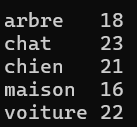

<br>

Temps d'exécution de 4.766s : <br>
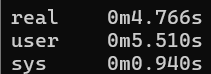


#### b) Fichier de taille N = 100 000 lignes


```bash
# Suppression des anciennes données
hdfs dfs -rm -r -f /user/oxfrz/output
hdfs dfs -rm -f /user/oxfrz/input/*

# Copie des données
hdfs dfs -put fichier2_100k.txt /user/oxfrz/input/

# Lancement du job MapReduce
time hadoop jar $HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar wordcount /user/oxfrz/input /user/oxfrz/output

# Visualisation des résultats
hdfs dfs -cat /user/oxfrz/output/part-r-00000

```

Occurrences obtenues : <br>
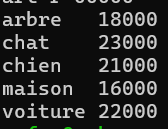

<br>

Temps d'exécution de 3.236s : <br>
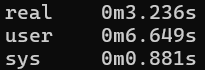

#### c) Fichier de taille N = 5 000 000 lignes


```bash
# Suppression des anciennes données
hdfs dfs -rm -r -f /user/oxfrz/output
hdfs dfs -rm -f /user/oxfrz/input/*

# Copie des données
hdfs dfs -put fichier3_5M.txt /user/oxfrz/input/

# Lancement du job MapReduce
time hadoop jar $HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar wordcount /user/oxfrz/input /user/oxfrz/output

# Visualisation des résultats
hdfs dfs -cat /user/oxfrz/output/part-r-00000

```

Occurrences obtenues : <br>
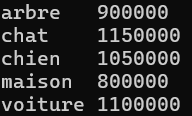

<br>

Temps d'exécution de 5.229s : <br>
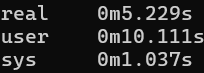

#### d) Fichier de taille N = 50 000 000 lignes


```bash
# Suppression des anciennes données
hdfs dfs -rm -r -f /user/oxfrz/output
hdfs dfs -rm -f /user/oxfrz/input/*

# Copie des données
hdfs dfs -put fichier4_50M.txt /user/oxfrz/input/

# Lancement du job MapReduce
time hadoop jar $HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar wordcount /user/oxfrz/input /user/oxfrz/output

# Visualisation des résultats
hdfs dfs -cat /user/oxfrz/output/part-r-00000

```

Occurrences obtenues : <br>
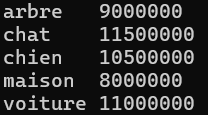

<br>

Temps d'exécution de 25.537s : <br>
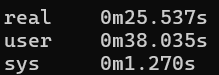

## **4 - Comparaison des méthodes**


| Nombre de lignes | Fichier | Séquentiel Python | Pseudo-MapReduce Python | Hadoop MapReduce |
| :--- | :--- | :---: | :---: | :---: |
| **100** | `fichier1_100.txt` | 0.01228 s | 0.00083 s | 4.766 s |
| **100 000** | `fichier2_100k.txt` | 0.04713 s | 0.06905 s | 3.236 s |
| **5 000 000** | `fichier3_5M.txt` | 0.71780 s | 2.48146 s | 5.229 s |
| **50 000 000** | `fichier4_50M.txt` | 7.60132 s | 23.38727 s | 25.537 s |

On pourrait s'attendre à ce que la méthode Hadoop ait de meilleurs résultats pour les fichiers 3 et/ou 4 (N= 5 000 000 et N= 50 000 000), cependant, ce n'est pas le cas ici. <br>
En effet, on a d'abord une latence au démarrage des processus distribués avec Hadoop. De plus, la taille du jeu de données n'est pas assez grande pour avoir une différence notable (il faudrait des fichiers de plusieurs gigaoctets pour obtenir de meilleures performances en utilisant la parallélisation).